In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors.csv


In [3]:
import io

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:
# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000



Missing values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Duplicate records: 0


In [5]:
# Dataset information
print("DATASET INFORMATION")
print("-" * 40)

df.info()

# Check missing values
print("\nMISSING VALUES")
print("-" * 40)

print(df.isnull().sum())

# Total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS")
print("-" * 40)

print("Duplicate rows:", df.duplicated().sum())

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

DATASET INFORMATION
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null  

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [6]:
# Select relevant columns
data = df[['Hours_Studied', 'Exam_Score']].copy()

# Display selected data
print("Selected dataset shape:", data.shape)

display(data.head())

Selected dataset shape: (6607, 2)


,Hours_Studied,Exam_Score
0,23,67
1,19,61
2,24,74
3,29,71
4,19,70


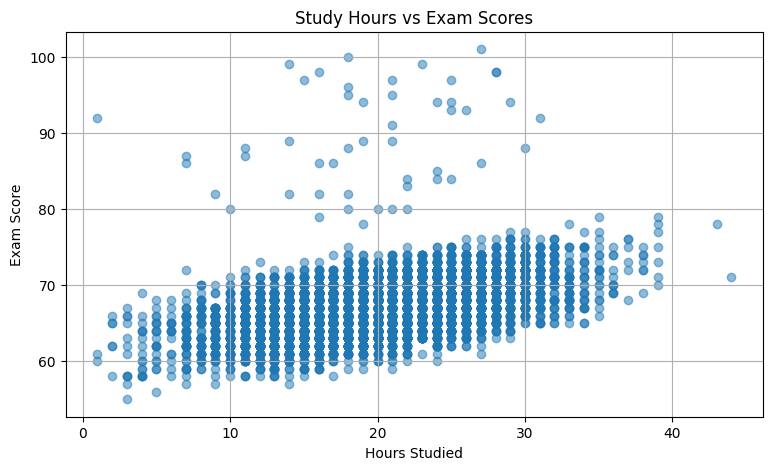

In [7]:
plt.figure(figsize=(9, 5))

plt.scatter(
    data['Hours_Studied'],
    data['Exam_Score'],
    alpha=0.5
)

plt.title('Study Hours vs Exam Scores')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')

plt.grid(True)
plt.show()

In [8]:
correlation = data['Hours_Studied'].corr(data['Exam_Score'])

print("Correlation between study hours and exam scores:", correlation)

Correlation between study hours and exam scores: 0.44545495407528235


In [9]:
# Check exam score distribution

print("Minimum exam score:", df['Exam_Score'].min())
print("Maximum exam score:", df['Exam_Score'].max())

# Find scores above 100
print("\nScores above 100:")

display(
    df[df['Exam_Score'] > 100][
        ['Hours_Studied', 'Exam_Score']
    ]
)

# Count scores above 100
print("\nNumber of scores above 100:",
      (df['Exam_Score'] > 100).sum())

Minimum exam score: 55
Maximum exam score: 101

Scores above 100:


,Hours_Studied,Exam_Score
1525,27,101



Number of scores above 100: 1


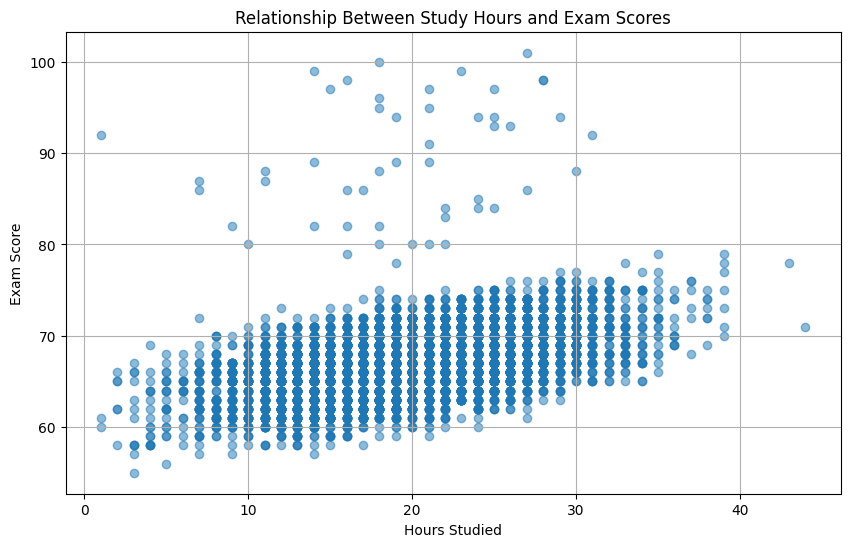

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    data['Hours_Studied'],
    data['Exam_Score'],
    alpha=0.5
)

plt.title('Relationship Between Study Hours and Exam Scores')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')

plt.grid(True)
plt.show()

In [11]:
correlation = data['Hours_Studied'].corr(
    data['Exam_Score']
)

print(f"Correlation: {correlation:.4f}")

Correlation: 0.4455


In [12]:
# Independent variable (input)
X = data[['Hours_Studied']]

# Dependent variable (target)
y = data['Exam_Score']

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (6607, 1)
Target (y): (6607,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5285
Testing samples: 1322


In [14]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

# Display model parameters
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Linear Regression model trained successfully!
Coefficient: 0.285668744443087
Intercept: 61.51116746904424


In [15]:
# Predict exam scores
y_pred = model.predict(X_test)

# Compare actual and predicted scores
comparison = pd.DataFrame({
    'Hours_Studied': X_test['Hours_Studied'].values,
    'Actual_Score': y_test.values,
    'Predicted_Score': np.round(y_pred, 2)
})

display(comparison.head(10))

,Hours_Studied,Actual_Score,Predicted_Score
0,20,65,67.22
1,22,65,67.80
2,21,71,67.51
3,12,64,64.94
4,21,66,67.51
5,21,66,67.51
6,37,72,72.08
7,24,66,68.37
8,17,70,66.37
9,16,70,66.08


In [16]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-" * 40)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MODEL EVALUATION
----------------------------------------
MAE:  2.4476
MSE:  10.8559
RMSE: 3.2948
R²:   0.2320


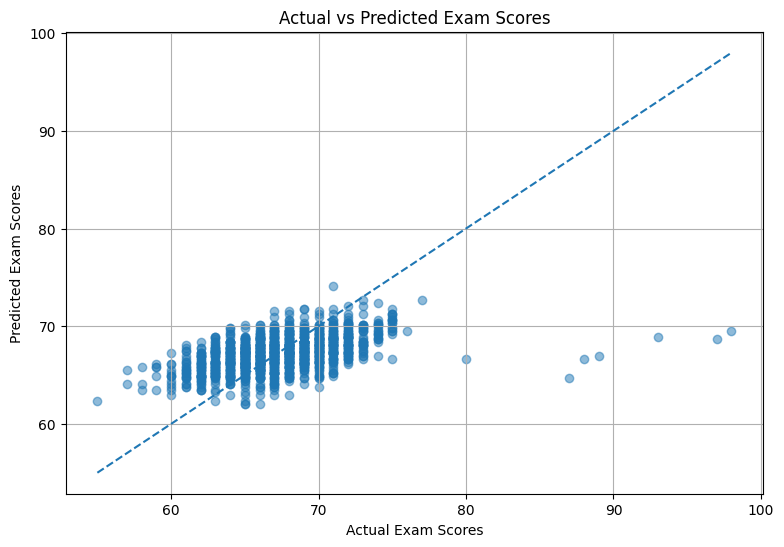

In [17]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title('Actual vs Predicted Exam Scores')
plt.xlabel('Actual Exam Scores')
plt.ylabel('Predicted Exam Scores')

plt.grid(True)
plt.show()

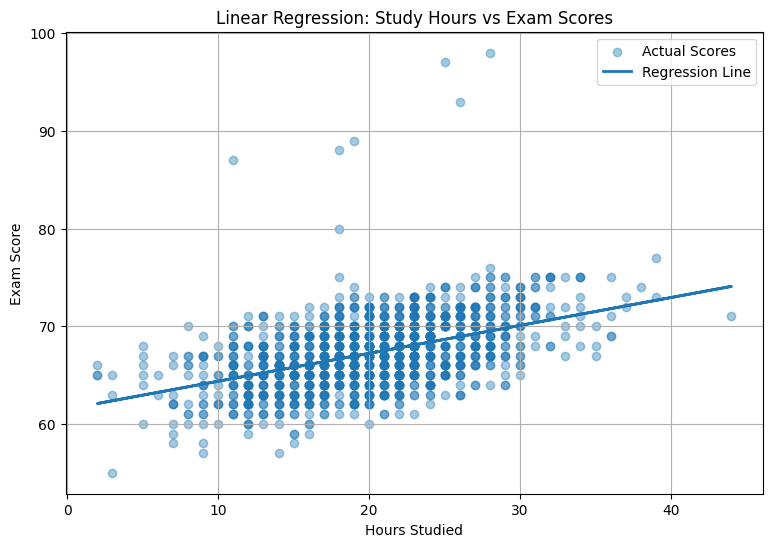

In [18]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_test['Hours_Studied'],
    y_test,
    alpha=0.4,
    label='Actual Scores'
)

plt.plot(
    X_test['Hours_Studied'],
    y_pred,
    linewidth=2,
    label='Regression Line'
)

plt.title('Linear Regression: Study Hours vs Exam Scores')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')

plt.legend()
plt.grid(True)
plt.show()

In [19]:
new_student = pd.DataFrame({
    'Hours_Studied': [25]
})

predicted_score = model.predict(new_student)

print("Study hours:", 25)
print("Predicted exam score:", round(predicted_score[0], 2))

Study hours: 25
Predicted exam score: 68.65


In [20]:
features = [
    'Hours_Studied',
    'Attendance',
    'Previous_Scores',
    'Sleep_Hours',
    'Tutoring_Sessions',
    'Physical_Activity'
]

X_multi = df[features]
y_multi = df['Exam_Score']

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi,
    test_size=0.20,
    random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train_multi, y_train_multi)

multi_pred = multi_model.predict(X_test_multi)

print("Multiple Linear Regression Results")
print("-" * 40)

print("MAE:", mean_absolute_error(y_test_multi, multi_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_multi, multi_pred)))
print("R2:", r2_score(y_test_multi, multi_pred))

Multiple Linear Regression Results
----------------------------------------
MAE: 1.2658558481860007
RMSE: 2.2506569657653466
R2: 0.6416391364668392


In [21]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2'],
    'Simple Linear Regression': [
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ],
    'Multiple Linear Regression': [
        mean_absolute_error(y_test_multi, multi_pred),
        np.sqrt(mean_squared_error(y_test_multi, multi_pred)),
        r2_score(y_test_multi, multi_pred)
    ]
})

display(comparison.round(4))

,Metric,Simple Linear Regression,Multiple Linear Regression
0,MAE,2.4476,1.2659
1,RMSE,3.2948,2.2507
2,R2,0.2320,0.6416


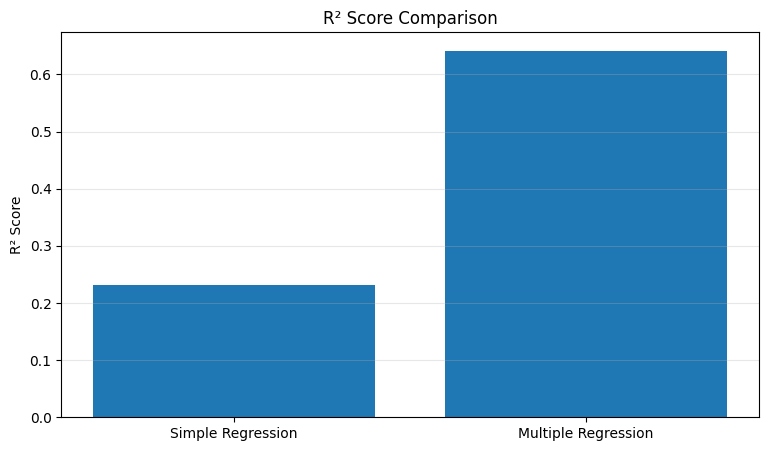

In [22]:
plt.figure(figsize=(9, 5))

plt.bar(
    ['Simple Regression', 'Multiple Regression'],
    [
        r2_score(y_test, y_pred),
        r2_score(y_test_multi, multi_pred)
    ]
)

plt.title('R² Score Comparison')
plt.ylabel('R² Score')
plt.grid(axis='y', alpha=0.3)
plt.show()

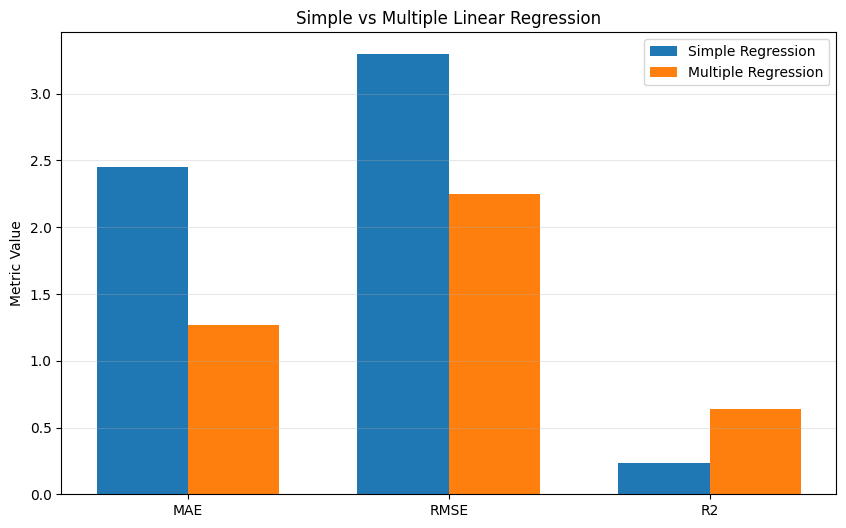

In [23]:
metrics = ['MAE', 'RMSE', 'R2']

simple_scores = [
    mean_absolute_error(y_test, y_pred),
    np.sqrt(mean_squared_error(y_test, y_pred)),
    r2_score(y_test, y_pred)
]

multiple_scores = [
    mean_absolute_error(y_test_multi, multi_pred),
    np.sqrt(mean_squared_error(y_test_multi, multi_pred)),
    r2_score(y_test_multi, multi_pred)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, simple_scores, width, label='Simple Regression')
plt.bar(x + width/2, multiple_scores, width, label='Multiple Regression')

plt.xticks(x, metrics)
plt.ylabel('Metric Value')
plt.title('Simple vs Multiple Linear Regression')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

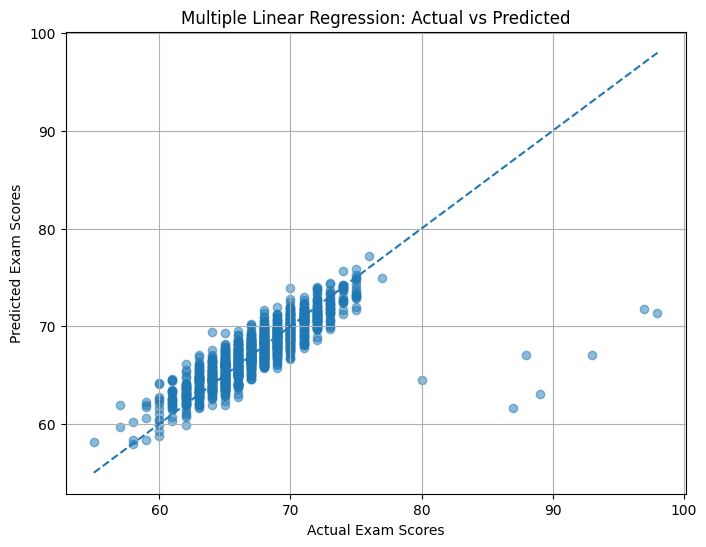

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test_multi, multi_pred, alpha=0.5)

plt.plot(
    [y_test_multi.min(), y_test_multi.max()],
    [y_test_multi.min(), y_test_multi.max()],
    linestyle='--'
)

plt.xlabel('Actual Exam Scores')
plt.ylabel('Predicted Exam Scores')
plt.title('Multiple Linear Regression: Actual vs Predicted')

plt.grid(True)
plt.show()

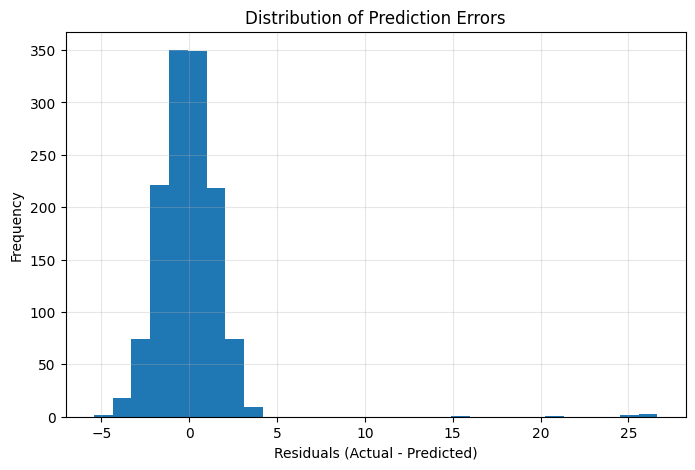

In [25]:
residuals = y_test_multi - multi_pred

plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30)

plt.title('Distribution of Prediction Errors')
plt.xlabel('Residuals (Actual - Predicted)')
plt.ylabel('Frequency')

plt.grid(alpha=0.3)
plt.show()

In [26]:
# Create residual analysis dataframe

residual_analysis = pd.DataFrame({
    'Actual_Score': y_test_multi.values,
    'Predicted_Score': multi_pred,
    'Residual': y_test_multi.values - multi_pred
})

residual_analysis['Absolute_Error'] = abs(
    residual_analysis['Residual']
)

# Display 15 largest prediction errors
largest_errors = residual_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
)

display(largest_errors.head(15))

,Actual_Score,Predicted_Score,Residual,Absolute_Error
704,98,71.341890,26.658110,26.658110
1144,93,67.002324,25.997676,25.997676
28,89,63.048357,25.951643,25.951643
1125,87,61.608532,25.391468,25.391468
721,97,71.805278,25.194722,25.194722
480,88,67.062139,20.937861,20.937861
945,80,64.469106,15.530894,15.530894
701,64,69.430952,-5.430952,5.430952
493,57,61.886747,-4.886747,4.886747
913,65,69.326540,-4.326540,4.326540


In [27]:
print("Exam scores above 75:")

display(
    df[df['Exam_Score'] > 75][
        ['Hours_Studied', 'Attendance',
         'Previous_Scores', 'Exam_Score']
    ].sort_values(
        by='Exam_Score',
        ascending=False
    )
)

Exam scores above 75:


,Hours_Studied,Attendance,Previous_Scores,Exam_Score
1525,27,98,93,101
94,18,89,73,100
2425,23,83,89,99
3579,14,90,86,99
4192,28,90,91,98
...,...,...,...,...
3602,32,98,89,76
5017,32,95,66,76
4697,28,99,100,76
6040,26,100,76,76


In [28]:
# Preserve original dataset indices
error_analysis = df.loc[X_test_multi.index].copy()

error_analysis['Predicted_Score'] = multi_pred

error_analysis['Residual'] = (
    y_test_multi - multi_pred
)

error_analysis['Absolute_Error'] = abs(
    error_analysis['Residual']
)

# Display students with the largest prediction errors
largest_errors = error_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
)

display(largest_errors.head(10))

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score,Predicted_Score,Residual,Absolute_Error
4192,28,90,Low,Medium,Yes,9,91,Medium,Yes,0,...,Positive,2,No,College,Moderate,Female,98,71.341890,26.658110,26.658110
4531,26,69,High,High,No,7,95,Low,No,0,...,Negative,3,No,Postgraduate,Near,Female,93,67.002324,25.997676,25.997676
217,19,70,Medium,Low,No,7,54,High,Yes,0,...,Positive,2,Yes,High School,Moderate,Male,89,63.048357,25.951643,25.951643
2687,11,71,Low,Medium,Yes,8,55,Medium,Yes,1,...,Negative,3,No,College,Near,Female,87,61.608532,25.391468,25.391468
5966,25,99,Medium,Medium,Yes,7,77,Medium,Yes,0,...,Neutral,3,No,High School,Near,Male,97,71.805278,25.194722,25.194722
2513,18,86,High,Medium,No,8,60,Medium,Yes,2,...,Neutral,1,No,College,Near,Male,88,67.062139,20.937861,20.937861
5989,18,61,Medium,Low,Yes,6,91,High,Yes,3,...,Positive,3,No,College,Moderate,Female,80,64.469106,15.530894,15.530894
5760,20,86,Low,Low,No,8,94,Low,Yes,2,...,Negative,2,No,High School,Far,Female,64,69.430952,-5.430952,5.430952
3543,14,67,Low,Low,Yes,7,66,Low,Yes,0,...,Neutral,4,No,High School,Far,Female,57,61.886747,-4.886747,4.886747
1042,26,88,Low,Low,No,10,67,Low,Yes,0,...,Positive,3,No,High School,Far,Male,65,69.326540,-4.326540,4.326540


In [29]:
# Analyze students with actual scores above 75
high_performers = error_analysis[
    error_analysis['Exam_Score'] > 75
].copy()

print("High-performing students in test set:",
      len(high_performers))

print("\nAverage actual score:",
      high_performers['Exam_Score'].mean())

print("\nAverage predicted score:",
      high_performers['Predicted_Score'].mean())

print("\nAverage prediction error:",
      high_performers['Residual'].mean())

High-performing students in test set: 9

Average actual score: 87.22222222222223

Average predicted score: 68.71691359561481

Average prediction error: 18.505308626607416


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate input features and target
X_full = df.drop(columns=['Exam_Score'])
y_full = df['Exam_Score']

# Identify numerical and categorical columns
numerical_features = X_full.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_full.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 6
Categorical features: 13

Categorical columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [31]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Create complete ML pipeline
full_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

print("Full preprocessing pipeline created successfully!")

Full preprocessing pipeline created successfully!


In [32]:
# Reuse the existing train/test indices
X_train_full = X_full.loc[X_train_multi.index]
X_test_full = X_full.loc[X_test_multi.index]

y_train_full = y_full.loc[X_train_multi.index]
y_test_full = y_full.loc[X_test_multi.index]

# Train model
full_model.fit(X_train_full, y_train_full)

# Predict
full_pred = full_model.predict(X_test_full)

print("Full-feature model trained successfully!")

Full-feature model trained successfully!


In [33]:
full_mae = mean_absolute_error(y_test_full, full_pred)

full_rmse = np.sqrt(
    mean_squared_error(y_test_full, full_pred)
)

full_r2 = r2_score(y_test_full, full_pred)

print("FULL-FEATURE LINEAR REGRESSION")
print("-" * 45)

print(f"MAE:  {full_mae:.4f}")
print(f"RMSE: {full_rmse:.4f}")
print(f"R2:   {full_r2:.4f}")

FULL-FEATURE LINEAR REGRESSION
---------------------------------------------
MAE:  0.4524
RMSE: 1.8044
R2:   0.7696


In [34]:
final_comparison = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Full-Feature Linear Regression'
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test_multi, multi_pred),
        full_mae
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test_multi, multi_pred)),
        full_rmse
    ],
    'R2': [
        r2_score(y_test, y_pred),
        r2_score(y_test_multi, multi_pred),
        full_r2
    ]
})

display(final_comparison.round(4))

,Model,MAE,RMSE,R2
0,Simple Linear Regression,2.4476,3.2948,0.2320
1,Multiple Linear Regression,1.2659,2.2507,0.6416
2,Full-Feature Linear Regression,0.4524,1.8044,0.7696


In [35]:
full_error_analysis = df.loc[X_test_full.index].copy()

full_error_analysis['Predicted_Score'] = full_pred

full_error_analysis['Residual'] = (
    y_test_full - full_pred
)

full_error_analysis['Absolute_Error'] = abs(
    full_error_analysis['Residual']
)

display(
    full_error_analysis.sort_values(
        by='Absolute_Error',
        ascending=False
    ).head(10)
)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score,Predicted_Score,Residual,Absolute_Error
217,19,70,Medium,Low,No,7,54,High,Yes,0,...,Positive,2,Yes,High School,Moderate,Male,89,60.989759,28.010241,28.010241
4192,28,90,Low,Medium,Yes,9,91,Medium,Yes,0,...,Positive,2,No,College,Moderate,Female,98,70.902730,27.097270,27.097270
2687,11,71,Low,Medium,Yes,8,55,Medium,Yes,1,...,Negative,3,No,College,Near,Female,87,60.105764,26.894236,26.894236
4531,26,69,High,High,No,7,95,Low,No,0,...,Negative,3,No,Postgraduate,Near,Female,93,67.554328,25.445672,25.445672
5966,25,99,Medium,Medium,Yes,7,77,Medium,Yes,0,...,Neutral,3,No,High School,Near,Male,97,73.039858,23.960142,23.960142
2513,18,86,High,Medium,No,8,60,Medium,Yes,2,...,Neutral,1,No,College,Near,Male,88,68.007096,19.992904,19.992904
5989,18,61,Medium,Low,Yes,6,91,High,Yes,3,...,Positive,3,No,College,Moderate,Female,80,64.929614,15.070386,15.070386
5725,13,73,Medium,High,No,8,93,Medium,Yes,0,...,Neutral,3,No,Postgraduate,NaN,Female,65,66.570881,-1.570881,1.570881
3543,14,67,Low,Low,Yes,7,66,Low,Yes,0,...,Neutral,4,No,High School,Far,Female,57,58.119570,-1.119570,1.119570
3686,35,68,Low,High,Yes,5,64,Medium,Yes,0,...,Positive,4,Yes,High School,Near,Male,67,68.098534,-1.098534,1.098534


In [36]:
high_performers_full = full_error_analysis[
    full_error_analysis['Exam_Score'] > 75
]

print("High-performing students:",
      len(high_performers_full))

print("Average actual score:",
      high_performers_full['Exam_Score'].mean())

print("Average predicted score:",
      high_performers_full['Predicted_Score'].mean())

print("Average absolute error:",
      high_performers_full['Absolute_Error'].mean())

High-performing students: 9
Average actual score: 87.22222222222223
Average predicted score: 68.69516473489699
Average absolute error: 18.570490248252227


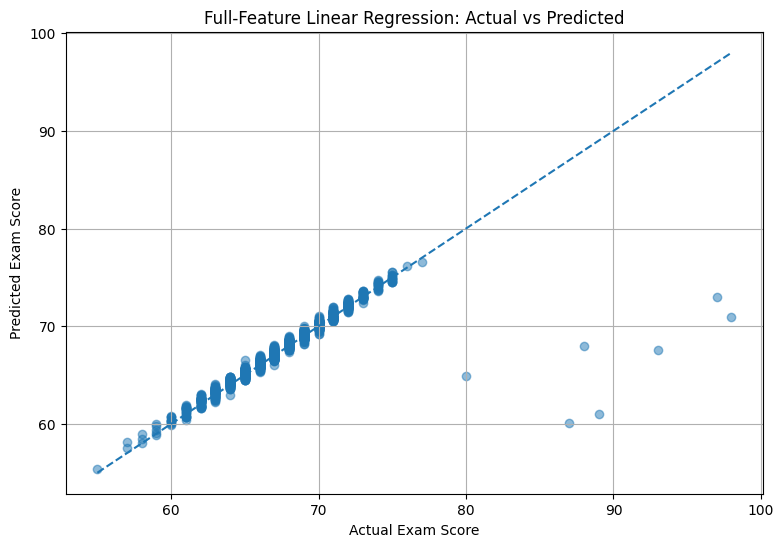

In [37]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test_full, full_pred, alpha=0.5)

plt.plot(
    [y_test_full.min(), y_test_full.max()],
    [y_test_full.min(), y_test_full.max()],
    linestyle='--'
)

plt.title('Full-Feature Linear Regression: Actual vs Predicted')
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')

plt.grid(True)
plt.show()

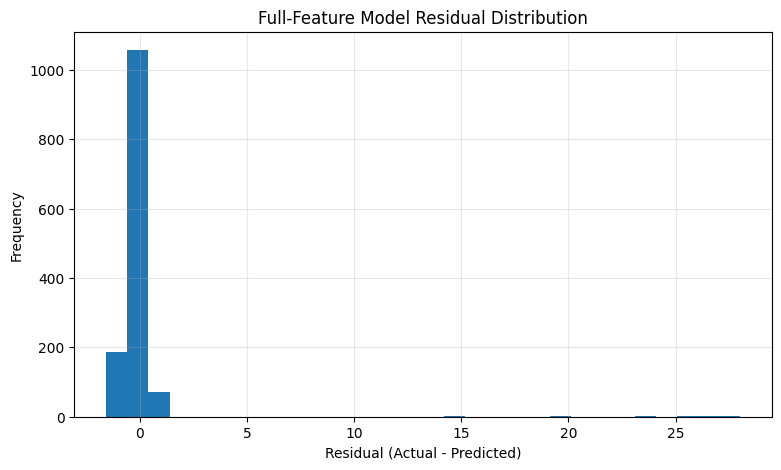

In [38]:
full_residuals = y_test_full - full_pred

plt.figure(figsize=(9, 5))

plt.hist(full_residuals, bins=30)

plt.title('Full-Feature Model Residual Distribution')
plt.xlabel('Residual (Actual - Predicted)')
plt.ylabel('Frequency')

plt.grid(alpha=0.3)
plt.show()